## Крок 0. Середовище

In [2]:
!nvidia-smi

Tue Oct 27 03:55:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P0             26W /   70W |     105MiB /  15360MiB |      3%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
import numba, numpy as np
from numba import cuda

print("numba", numba.__version__)
print("cuda.is_available:", cuda.is_available())
dev = cuda.get_current_device()
KARTA = dev.name.decode() if isinstance(dev.name, bytes) else dev.name
print("карта:", KARTA)
print("мультипроцесорів (SM):", dev.MULTIPROCESSOR_COUNT, "| розмір варпу:", dev.WARP_SIZE)

numba 0.61.2
cuda.is_available: True
карта: Tesla T4
мультипроцесорів (SM): 40 | розмір варпу: 32


## Крок 1. Ядро


In [3]:
@cuda.jit
def mandelbrot_gpu(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)
    if x >= out.shape[1] or y >= out.shape[0]:
        return
    cx = xmin + (xmax - xmin) * x / out.shape[1]
    cy = ymin + (ymax - ymin) * y / out.shape[0]
    zx = 0.0
    zy = 0.0
    n = 0
    while zx * zx + zy * zy <= 4.0 and n < max_iter:
        zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
        n += 1
    out[y, x] = n

сітка: (75, 50) блоків × (16, 16) потоків = 960000 потоків на 960000 точок
out.min = 1 | out.max = 300


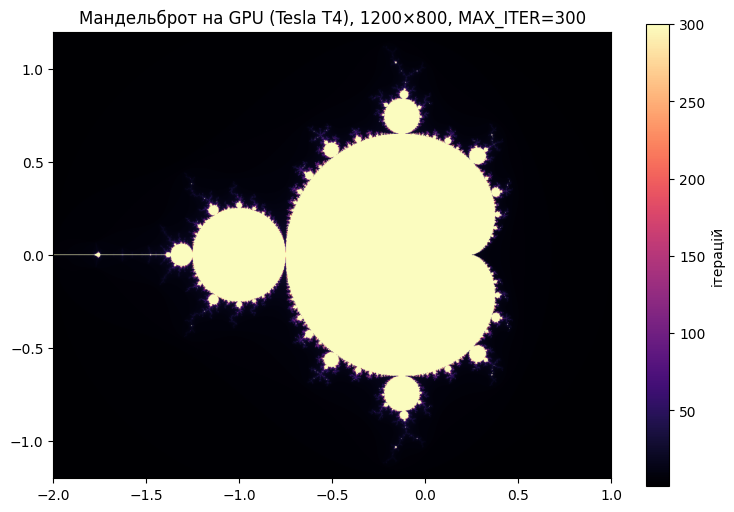

In [4]:
XMIN, XMAX, YMIN, YMAX = -2.0, 1.0, -1.2, 1.2
MAX_ITER = 300
W, H = 1200, 800

potokiv = (16, 16)
blokiv = ((W + 15) // 16, (H + 15) // 16)
print("сітка:", blokiv, "блоків ×", potokiv, "потоків =", blokiv[0]*blokiv[1]*256, "потоків на", W*H, "точок")

d_out = cuda.device_array((H, W), dtype=np.int32)
mandelbrot_gpu[blokiv, potokiv](d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
out = d_out.copy_to_host()
print("out.min =", out.min(), "| out.max =", out.max())

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
plt.imshow(out, cmap="magma", extent=(XMIN, XMAX, YMIN, YMAX))
plt.colorbar(label="ітерацій")
plt.title(f"Мандельброт на GPU ({KARTA}), {W}×{H}, MAX_ITER={MAX_ITER}")
plt.show()

## Крок 2. Еталон на CPU у тому самому зошиті

In [5]:
from numba import njit, prange
import time, os

@njit(parallel=True, cache=True)
def mandelbrot_cpu(W, H, xmin, xmax, ymin, ymax, max_iter):
    out = np.empty((H, W), np.int32)
    for j in prange(H):
        for i in range(W):
            cx = xmin + (xmax - xmin) * i / W
            cy = ymin + (ymax - ymin) * j / H
            zx = 0.0
            zy = 0.0
            n = 0
            while zx * zx + zy * zy <= 4.0 and n < max_iter:
                zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
                n += 1
            out[j, i] = n
    return out

mandelbrot_cpu(16, 16, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
ref = mandelbrot_cpu(W, H, XMIN, XMAX, YMIN, YMAX, MAX_ITER)

rozbizhnyh = int((out != ref).sum())
print("розбіжних точок:", rozbizhnyh, "з", W * H)

def zamir_cpu(W, H, n=3):
    best = None
    for _ in range(n):
        t0 = time.perf_counter()
        mandelbrot_cpu(W, H, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
        t = time.perf_counter() - t0
        best = t if best is None else min(best, t)
    return best

t_cpu = zamir_cpu(W, H)
print(f"njit(parallel=True) на CPU Colab ({os.cpu_count()} логічних ядер, numba-потоків: {numba.get_num_threads()}): "
      f"{t_cpu*1000:.2f} мс, {W}×{H}, мінімум із 3")
!lscpu | grep -E "Model name|^CPU\(s\)"

розбіжних точок: 2 з 960000
njit(parallel=True) на CPU Colab (2 логічних ядер, numba-потоків: 2): 175.09 мс, 1200×800, мінімум із 3
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


## Крок 3. Три складові часу

In [6]:
def zamir_gpu(W, H, blok=(16, 16), n=3, kernel=None, args=None):
    kernel = kernel or mandelbrot_gpu
    args = args or (XMIN, XMAX, YMIN, YMAX, MAX_ITER)
    host = np.empty((H, W), np.int32)
    blokiv = ((W + blok[0] - 1) // blok[0], (H + blok[1] - 1) // blok[1])
    best = None
    for _ in range(n):
        t0 = time.perf_counter()
        d_out = cuda.to_device(host)
        cuda.synchronize()
        t_tudy = time.perf_counter() - t0

        t0 = time.perf_counter()
        kernel[blokiv, blok](d_out, *args)
        cuda.synchronize()
        t_yadro = time.perf_counter() - t0

        t0 = time.perf_counter()
        res = d_out.copy_to_host()
        t_nazad = time.perf_counter() - t0

        if best is None or sum(best[:3]) > t_tudy + t_yadro + t_nazad:
            best = (t_tudy, t_yadro, t_nazad, res)
    return best

t_tudy, t_yadro, t_nazad, out = zamir_gpu(W, H)
razom = t_tudy + t_yadro + t_nazad
chastka = 100 * (t_tudy + t_nazad) / razom
print(f"{W}×{H}, блок 16×16, мінімум із 3 прогонів")
print(f"копіювання туди   {t_tudy*1000:8.2f} мс")
print(f"обчислення        {t_yadro*1000:8.2f} мс")
print(f"копіювання назад  {t_nazad*1000:8.2f} мс")
print(f"разом             {razom*1000:8.2f} мс   копіювання = {chastka:.0f} %")
print(f"розбіжних із CPU: {int((out != ref).sum())}")

1200×800, блок 16×16, мінімум із 3 прогонів
копіювання туди       1.33 мс
обчислення           15.31 мс
копіювання назад      1.34 мс
разом                17.99 мс   копіювання = 15 %
розбіжних із CPU: 2


In [7]:
d = cuda.to_device(np.empty((H, W), np.int32))
cuda.synchronize()
t0 = time.perf_counter()
mandelbrot_gpu[blokiv, potokiv](d, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
bez = time.perf_counter() - t0
cuda.synchronize()
z = time.perf_counter() - t0
print(f"без synchronize {bez*1000:.3f} мс · з synchronize {z*1000:.3f} мс · різниця ×{z/bez:.0f}")

без synchronize 0.338 мс · з synchronize 15.489 мс · різниця ×46


## Крок 4. Три розміри задачі

In [8]:
rozmiry = ((300, 200), (1200, 800), (3000, 2000))
rez = {}
print("| розмір | туди, мс | ядро, мс | назад, мс | частка копіювання |")
print("|---|---|---|---|---|")
for w, h in rozmiry:
    tt, ty, tn, _ = zamir_gpu(w, h)
    s = tt + ty + tn
    rez[(w, h)] = (tt, ty, tn)
    print(f"| {w}x{h} | {tt*1000:.2f} | {ty*1000:.2f} | {tn*1000:.2f} | {100*(tt+tn)/s:.0f} % |")

| розмір | туди, мс | ядро, мс | назад, мс | частка копіювання |
|---|---|---|---|---|
| 300x200 | 0.33 | 2.13 | 0.13 | 18 % |
| 1200x800 | 1.32 | 15.28 | 1.07 | 14 % |
| 3000x2000 | 7.62 | 41.54 | 6.24 | 25 % |


In [9]:
print("| розмір | CPU njit, мс | GPU ядро, мс | GPU з копіюванням, мс | ×ядро | ×з копіюванням |")
print("|---|---|---|---|---|---|")
for w, h in rozmiry:
    tc = zamir_cpu(w, h)
    tt, ty, tn = rez[(w, h)]
    print(f"| {w}x{h} | {tc*1000:.2f} | {ty*1000:.2f} | {(tt+ty+tn)*1000:.2f} | ×{tc/ty:.1f} | ×{tc/(tt+ty+tn):.1f} |")

| розмір | CPU njit, мс | GPU ядро, мс | GPU з копіюванням, мс | ×ядро | ×з копіюванням |
|---|---|---|---|---|---|
| 300x200 | 11.81 | 2.13 | 2.58 | ×5.6 | ×4.6 |
| 1200x800 | 174.93 | 15.28 | 17.67 | ×11.4 | ×9.9 |
| 3000x2000 | 1090.23 | 41.54 | 55.40 | ×26.2 | ×19.7 |


## Крок 5. Рядки для `zamiry.md`

In [10]:
print(f"| GPU, лише ядро (07) | {W}x{H} | {t_yadro*1000:.2f} мс | карта: {KARTA}, Colab; float64, блок 16×16, мін. із 3, з cuda.synchronize() |")
print(f"| GPU, з копіюванням (07) | {W}x{H} | {razom*1000:.2f} мс | те саме; туди + ядро + назад, копіювання {chastka:.0f} % |")
print()
print(f"> Процесорні рядки заміряні на ноутбуці, GPU — на машині Colab ({KARTA}). Це різні машини. "
      f"Порівняння на одній машині (Colab): njit(parallel=True) {t_cpu*1000:.2f} мс проти ядра {t_yadro*1000:.2f} мс (×{t_cpu/t_yadro:.1f}).")

| GPU, лише ядро (07) | 1200x800 | 15.31 мс | карта: Tesla T4, Colab; float64, блок 16×16, мін. із 3, з cuda.synchronize() |
| GPU, з копіюванням (07) | 1200x800 | 17.99 мс | те саме; туди + ядро + назад, копіювання 15 % |

> Процесорні рядки заміряні на ноутбуці, GPU — на машині Colab (Tesla T4). Це різні машини. Порівняння на одній машині (Colab): njit(parallel=True) 175.09 мс проти ядра 15.31 мс (×11.4).


## Крок 6. Підсумок і рядок у чат

In [11]:
print(f"Булатникова · карта {KARTA} · ядро {t_yadro*1000:.1f} мс · копіювання {chastka:.0f} % "
      f"· GPU/njit ×{t_cpu/t_yadro:.0f} · розбіжних {rozbizhnyh}")

Булатникова · карта Tesla T4 · ядро 15.3 мс · копіювання 15 % · GPU/njit ×11 · розбіжних 2


---
# Додаткові завдання

### 1. Розмір блока

In [12]:
print("| блок | потоків | варпів | ядро, мс | розбіжних |")
print("|---|---|---|---|---|")
for b in ((8, 8), (16, 16), (32, 32), (10, 10)):
    _, ty, _, r = zamir_gpu(W, H, blok=b)
    p = b[0] * b[1]
    print(f"| {b[0]}×{b[1]} | {p} | {p/32:.3f} | {ty*1000:.2f} | {int((r != ref).sum())} |")
print("10×10: останній варп —", 100 - 3*32, "робочих потоків із 32,", 32 - (100 - 3*32), "даремних")

| блок | потоків | варпів | ядро, мс | розбіжних |
|---|---|---|---|---|
| 8×8 | 64 | 2.000 | 14.92 | 2 |
| 16×16 | 256 | 8.000 | 15.32 | 2 |
| 32×32 | 1024 | 32.000 | 16.63 | 2 |
| 10×10 | 100 | 3.125 | 18.83 | 2 |
10×10: останній варп — 4 робочих потоків із 32, 28 даремних


### 2. float32 замість float64

In [13]:
f32 = np.float32

@cuda.jit
def mandelbrot_gpu32(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)
    h = out.shape[0]
    w = out.shape[1]
    if x >= w or y >= h:
        return
    cx = xmin + (xmax - xmin) * f32(x) / f32(w)
    cy = ymin + (ymax - ymin) * f32(y) / f32(h)
    zx = f32(0.0)
    zy = f32(0.0)
    n = 0
    while zx * zx + zy * zy <= f32(4.0) and n < max_iter:
        zx, zy = zx * zx - zy * zy + cx, f32(2.0) * zx * zy + cy
        n += 1
    out[y, x] = n

args32 = (f32(XMIN), f32(XMAX), f32(YMIN), f32(YMAX), MAX_ITER)
_, ty32, _, r32 = zamir_gpu(W, H, kernel=mandelbrot_gpu32, args=args32)
r32_bad = int((r32 != ref).sum())
print(f"ядро float64 {t_yadro*1000:.2f} мс · float32 {ty32*1000:.2f} мс · ×{t_yadro/ty32:.1f}")
print(f"розбіжних із CPU-еталоном (float64): {r32_bad} з {W*H} ({100*r32_bad/(W*H):.2f} %)")

ядро float64 15.31 мс · float32 0.62 мс · ×24.8
розбіжних із CPU-еталоном (float64): 2534 з 960000 (0.26 %)


### 3. Чи впираємось у шину

In [14]:
mib = W * H * 4 / 2**20
gb = W * H * 4 / 1e9
print(f"масив {W}×{H} int32 = {mib:.2f} МіБ")
print(f"туди  {gb/t_tudy:.2f} ГБ/с · назад {gb/t_nazad:.2f} ГБ/с · теоретично PCIe 3.0 ×16 ≈ 15.75 ГБ/с")

pinned = cuda.pinned_array((H, W), dtype=np.int32)
best_t, best_n = None, None
for _ in range(3):
    t0 = time.perf_counter(); dp = cuda.to_device(pinned); cuda.synchronize(); a = time.perf_counter() - t0
    t0 = time.perf_counter(); dp.copy_to_host(pinned); b = time.perf_counter() - t0
    best_t = a if best_t is None else min(best_t, a)
    best_n = b if best_n is None else min(best_n, b)
print(f"pinned: туди {gb/best_t:.2f} ГБ/с · назад {gb/best_n:.2f} ГБ/с")

масив 1200×800 int32 = 3.66 МіБ
туди  2.88 ГБ/с · назад 2.86 ГБ/с · теоретично PCIe 3.0 ×16 ≈ 15.75 ГБ/с
pinned: туди 4.78 ГБ/с · назад 11.11 ГБ/с


### 4. Де перетин GPU і ноутбука

У `noutbuk_ms` — числа `njit(parallel=True)` з тижня 6 (ноутбук) для тих самих розмірів; порожні значення пропускаються.

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 28 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


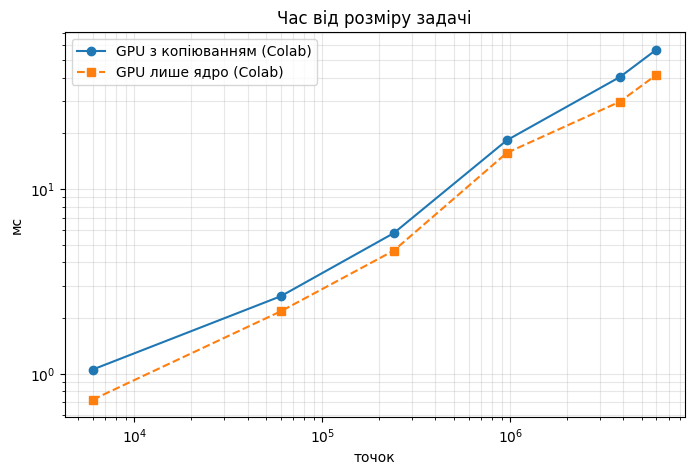

100x60: GPU повний 1.05 мс · ядро 0.72 мс · ноутбук None
300x200: GPU повний 2.62 мс · ядро 2.17 мс · ноутбук None
600x400: GPU повний 5.77 мс · ядро 4.64 мс · ноутбук None
1200x800: GPU повний 18.37 мс · ядро 15.69 мс · ноутбук None
2400x1600: GPU повний 40.44 мс · ядро 29.74 мс · ноутбук None
3000x2000: GPU повний 56.87 мс · ядро 41.53 мс · ноутбук None


In [15]:
rozmiry4 = ((100, 60), (300, 200), (600, 400), (1200, 800), (2400, 1600), (3000, 2000))
noutbuk_ms = {r: None for r in rozmiry4}

gpu_full, gpu_kernel = [], []
for w, h in rozmiry4:
    tt, ty, tn, _ = zamir_gpu(w, h)
    gpu_full.append((tt + ty + tn) * 1000); gpu_kernel.append(ty * 1000)

tochok = [w * h for w, h in rozmiry4]
plt.figure(figsize=(8, 5))
plt.loglog(tochok, gpu_full, "o-", label="GPU з копіюванням (Colab)")
plt.loglog(tochok, gpu_kernel, "s--", label="GPU лише ядро (Colab)")
nb = [(p, noutbuk_ms[r]) for p, r in zip(tochok, rozmiry4) if noutbuk_ms[r]]
if nb:
    plt.loglog(*zip(*nb), "^-", label="njit(parallel=True), ноутбук")
plt.xlabel("точок"); plt.ylabel("мс"); plt.legend(); plt.grid(True, which="both", alpha=.3)
plt.title("Час від розміру задачі")
plt.show()
for r, f, k in zip(rozmiry4, gpu_full, gpu_kernel):
    print(f"{r[0]}x{r[1]}: GPU повний {f:.2f} мс · ядро {k:.2f} мс · ноутбук {noutbuk_ms[r]}")